# Braun et al. (2026), Supp. Fig. 9 — effect of perturbations on the RNN dynamics (WP0.5)

> A: correlation after silencing, against the perturbation window relative to the ensemble's active window, for
> ensembles of 10, 20, 30% (1.7 s windows). B: the same for current injection (I = 3). C: current injection with
> I = 0.5, 2, 5 (20% ensembles). D: example responses to noise injected into 10–75% of neurons with gains 5–20 during
> the first 8.5 s. E: correlation over gain × fraction. F–K (bat, mouse) are blocked on [DATA].

**Panels:** A silencing · B current I = 3 · C current magnitudes · D noise examples · E noise grid.

**Expected (legend):** silencing the active ensemble drops the correlation to ~0 (more negative for larger ensembles),
else ~1; current into inactive ensembles gives negative correlation (reset), into the active ensemble ~1, independent of
ensemble size; I = 0.5 has no effect; noise leaves the sequence intact.
Same network and protocol as the Fig. 4 notebook (`configs/wp0/braun_fig4.yaml`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from seqnet.figures import Figure, style
from seqnet.experiments import wp0
from seqnet.targets import SequenceSpec
from seqnet.models.rate_rnn import RNNParams
from seqnet.analysis import perturb as pt

style()
fig = Figure("wp0", "braun_supp9")
cfg = Figure("wp0", "braun_fig4").config(); tg = cfg["target"]
run = wp0.get(tg["amp"], tg["width"], tg["offset"], cfg["settings"])
J = run.W(cfg["realisation"]); spec = SequenceSpec(amp=tg["amp"], width=tg["width"], offset=tg["offset"])
h0 = spec.h_target(np.array([0.0]))[:, 0]; prm = RNNParams()
kw = dict(params=prm, n_steps=cfg["n_steps"], window_steps=cfg["window_steps"], n_windows=cfg["n_windows"], seed=cfg["seed"])

## Panels A–C — structured perturbations, aligned correlation curves

In [2]:
curves = {}
for f in (0.1, 0.2, 0.3):
    curves[f"silence_{f}"] = pt.structured_grid(J, h0, "silence", f, **kw).aligned_mean
    curves[f"current3_{f}"] = pt.structured_grid(J, h0, "current", f, amplitude=3.0, **kw).aligned_mean
for I in (0.5, 2.0, 5.0):
    curves[f"currentI_{I}"] = pt.structured_grid(J, h0, "current", 0.2, amplitude=I, **kw).aligned_mean
fig.save("ABC_structured", **curves)

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_supp9/ABC_structured.npz')

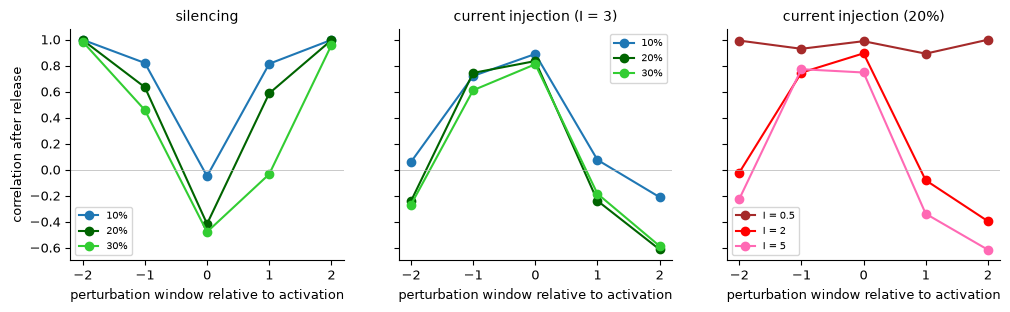

In [3]:
d = fig.load("ABC_structured"); x = np.arange(-2, 3)
F, axs = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for f, c in zip((0.1, 0.2, 0.3), ("tab:blue", "darkgreen", "limegreen")):
    axs[0].plot(x, d[f"silence_{f}"], "o-", color=c, label=f"{int(f*100)}%"); axs[1].plot(x, d[f"current3_{f}"], "o-", color=c, label=f"{int(f*100)}%")
for I, c in zip((0.5, 2.0, 5.0), ("brown", "red", "hotpink")):
    axs[2].plot(x, d[f"currentI_{I}"], "o-", color=c, label=f"I = {I:g}")
for ax, t in zip(axs, ["silencing", "current injection (I = 3)", "current injection (20%)"]):
    ax.set_title(t); ax.set_xlabel("perturbation window relative to activation"); ax.legend(fontsize=7); ax.axhline(0, color="0.7", lw=0.5)
axs[0].set_ylabel("correlation after release")
fig.savefig("ABC_structured", F); plt.show()

## Panels D–E — noise injection into a random fraction of neurons during the first 8.5 s

In [4]:
fracs, gains = [0.1, 0.25, 0.5, 0.75], [5.0, 10.0, 15.0, 20.0]
C = np.zeros((len(gains), len(fracs))); ex = {}
for i, g in enumerate(gains):
    for j, f in enumerate(fracs):
        out = pt.unstructured(J, h0, f, g, params=prm, n_steps=cfg["n_steps"], seed=cfg["seed"])
        C[i, j] = out["corr"]
        if (g, f) in [(5.0, 0.1), (20.0, 0.75), (15.0, 0.5)]:
            ex[f"r_g{g:g}_f{f:g}"] = out["r"][::4].T.astype(np.float32)
fig.save("DE_noise", gains=np.array(gains), fracs=np.array(fracs), C=C, **ex)

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_supp9/DE_noise.npz')

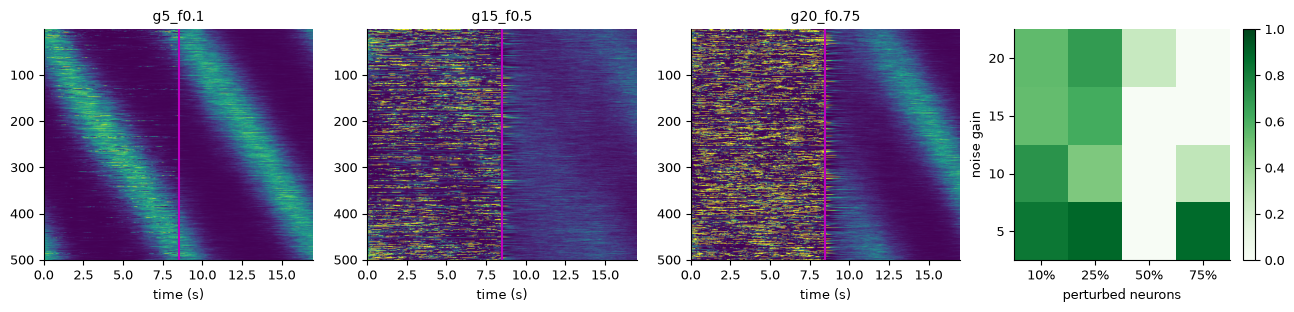

[[ 0.83   0.889 -0.421  0.877]
 [ 0.716  0.471 -0.556  0.27 ]
 [ 0.537  0.617 -0.158 -0.224]
 [ 0.547  0.684  0.247 -0.345]]


In [5]:
d = fig.load("DE_noise")
keys = [k for k in d if k.startswith("r_")]
F, axs = plt.subplots(1, len(keys) + 1, figsize=(4 * (len(keys) + 1), 3))
for ax, k in zip(axs, keys):
    ax.imshow(d[k], aspect="auto", extent=[0, 17, 501, 1], vmin=0, vmax=1); ax.axvline(8.5, color="m"); ax.set_title(k[2:]); ax.set_xlabel("time (s)")
im = axs[-1].imshow(d["C"], origin="lower", aspect="auto", cmap="Greens", vmin=0, vmax=1)
axs[-1].set_xticks(range(len(d["fracs"])), [f"{int(f*100)}%" for f in d["fracs"]]); axs[-1].set_yticks(range(len(d["gains"])), [f"{g:g}" for g in d["gains"]])
axs[-1].set_xlabel("perturbed neurons"); axs[-1].set_ylabel("noise gain"); F.colorbar(im, ax=axs[-1])
fig.savefig("DE_noise", F); plt.show()
print(np.round(d["C"], 3))

## Acceptance (qualitative, from the legend)

In [6]:
a = fig.load("ABC_structured"); n = fig.load("DE_noise")
fig.checks([
    {"item": "silencing the active ensemble drops correlation; off-window ~1", "criterion": "centre < 0.5, edges > 0.8 for 10-30%",
     "value": {f: a[f"silence_{f}"] for f in (0.1, 0.2, 0.3)}, "passed": bool(all(a[f"silence_{f}"][2] < 0.5 and min(a[f"silence_{f}"][[0, 4]]) > 0.8 for f in (0.1, 0.2, 0.3)))},
    {"item": "larger silenced ensembles give lower correlation", "criterion": "centre value decreasing with ensemble size",
     "value": [float(a[f"silence_{f}"][2]) for f in (0.1, 0.2, 0.3)], "passed": bool(a["silence_0.1"][2] >= a["silence_0.2"][2] >= a["silence_0.3"][2])},
    {"item": "current into the active ensemble ~1, into inactive ones resets (negative)", "criterion": "centre > 0.8 and min(edges) < 0 for I = 3",
     "value": {f: a[f"current3_{f}"] for f in (0.1, 0.2, 0.3)}, "passed": bool(all(a[f"current3_{f}"][2] > 0.8 and a[f"current3_{f}"].min() < 0 for f in (0.1, 0.2, 0.3)))},
    {"item": "I = 0.5 has no effect", "criterion": "all > 0.9", "value": a["currentI_0.5"], "passed": bool(a["currentI_0.5"].min() > 0.9)},
    {"item": "noise leaves the sequence intact", "criterion": "reported; legend: 'sequences always continue'", "value": n["C"], "passed": None},
])

[PASS] silencing the active ensemble drops correlation; off-window ~1: {0.1: array([ 0.99834003,  0.8200975 , -0.04930409,  0.8139846 ,  0.99768071]), 0.2: array([ 0.99649384,  0.63371783, -0.41598136,  0.58684867,  0.99502583]), 0.3: array([ 0.9839628 ,  0.45819947, -0.47789458, -0.0338999 ,  0.95656502])}
[PASS] larger silenced ensembles give lower correlation: [-0.04930408786983398, -0.4159813561116262, -0.4778945768346425]
[PASS] current into the active ensemble ~1, into inactive ones resets (negative): {0.1: array([ 0.0596129 ,  0.72040105,  0.88933012,  0.07559794, -0.21077787]), 0.2: array([-0.24156933,  0.74373456,  0.83495764, -0.23865076, -0.61262056]), 0.3: array([-0.26899996,  0.61057569,  0.81038094, -0.18464776, -0.5862133 ])}
[FAIL] I = 0.5 has no effect: [0.99236627 0.92908754 0.98761261 0.89174394 0.9988425 ]
[info] noise leaves the sequence intact: [[ 0.83046165  0.88925746 -0.4208539   0.87659623]
 [ 0.71629954  0.47101065 -0.55605364  0.27022446]
 [ 0.53723061  0.61

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_supp9/acceptance.json')